In [1]:
from sklearn.datasets import make_regression
import numpy as np

In [3]:
X, y = make_regression(n_samples=4, n_features=1, noise=80, n_targets=1, random_state=13)

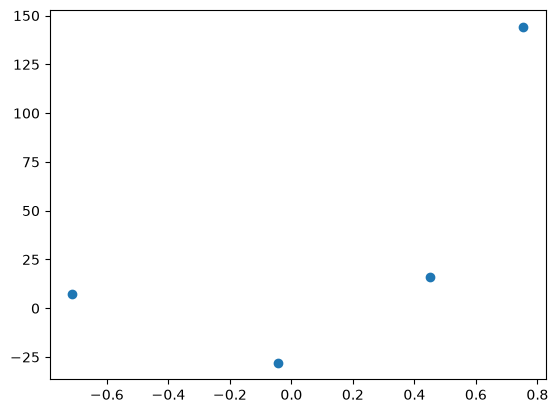

In [6]:
import matplotlib.pyplot as plt
plt.scatter(X, y)

In [7]:
#lets apply OLS
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [8]:
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[78.35]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,26.16
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[1.11]


In [10]:
model.coef_

array([78.35063668])

In [11]:
model.intercept_

np.float64(26.15963284313262)

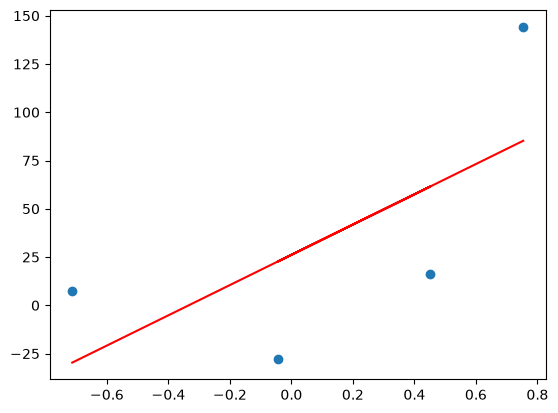

In [12]:
plt.scatter(X, y)
plt.plot(X, model.predict(X), color='red')

In [13]:
# Lets apply Gradient Descent assuming slope is constant  m= 78.35
# and lets assume the starting value for intercept b = 0

y_pred = (78.35 * X + 0).reshape(4)
y_pred

array([-55.81580837,  35.39949674,  -3.48681619,  59.05759577])

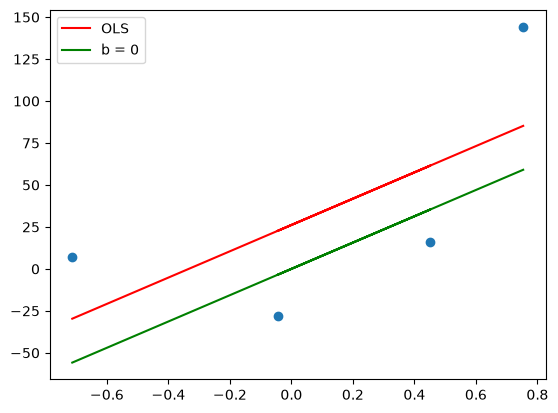

In [14]:
from cProfile import label


plt.scatter(X, y)
plt.plot(X, model.predict(X), color='red', label='OLS')
plt.plot(X, y_pred, color='green', label='b = 0')
plt.legend()
plt.show()

In [15]:
m= 78.35
b = 0

loss_slppoe = -2* np.sum(y-m*X.ravel()- b)
loss_slppoe

np.float64(-209.27763408209216)

In [16]:
#lets Take learning rate = 0.1

lr = 0.1

step_size = loss_slppoe*lr
step_size

np.float64(-20.927763408209216)

In [17]:
# Calculating The new intercept
b = b - step_size
b

np.float64(20.927763408209216)

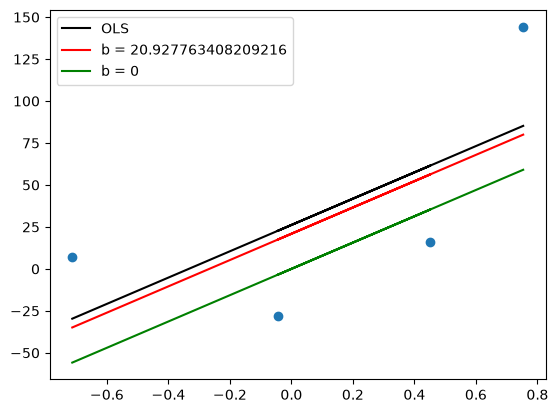

In [21]:
y_pred1 = (78.35 * X + b).reshape(4)

plt.scatter(X, y)
plt.plot(X, model.predict(X), color='black', label='OLS')
plt.plot(X, y_pred1, color='red', label='b = {}'.format(b))
plt.plot(X, y_pred, color='green', label='b = 0')
plt.legend()
plt.show()

In [22]:
# Itration 2
loss_slppoe = -2* np.sum(y-m*X.ravel()- b)
loss_slppoe

np.float64(-41.85552681641843)

In [23]:
step_size = loss_slppoe*lr
step_size


np.float64(-4.185552681641844)

In [24]:
b = b - step_size
b

np.float64(25.11331608985106)

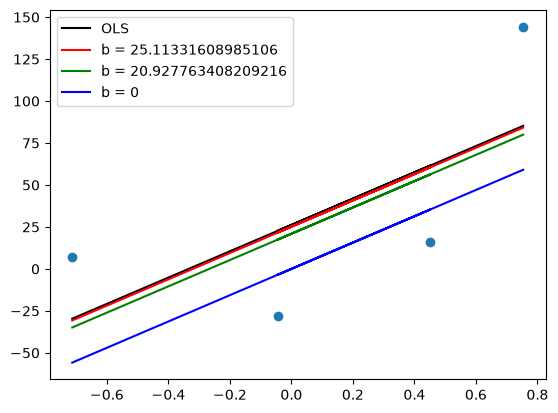

In [27]:
y_pred2 = (78.35 * X + b).reshape(4)

plt.scatter(X, y)
plt.plot(X, model.predict(X), color='black', label='OLS')
plt.plot(X, y_pred2, color='red', label='b = {}'.format(b))
plt.plot(X, y_pred1, color='green', label='b = {}'.format(b+step_size))
plt.plot(X, y_pred, color='blue', label='b = 0')
plt.legend()
plt.show()

In [28]:
# Itration 3 
loss_slppoe = -2* np.sum(y-m*X.ravel()- b)

step_size = loss_slppoe*lr
b = b - step_size


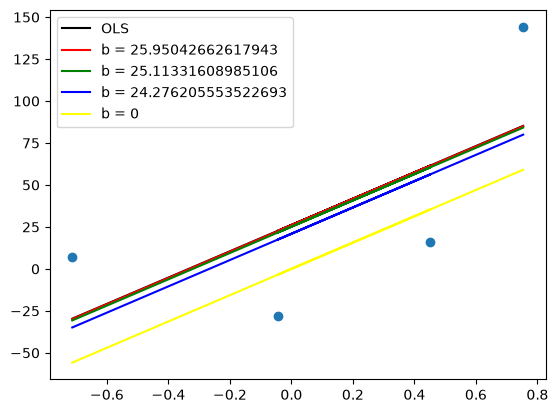

In [29]:
y_pred3 = (78.35 * X + b).reshape(4)


plt.scatter(X, y)
plt.plot(X, model.predict(X), color='black', label='OLS')
plt.plot(X, y_pred3, color='red', label='b = {}'.format(b))
plt.plot(X, y_pred2, color='green', label='b = {}'.format(b+step_size))
plt.plot(X, y_pred1, color='blue', label='b = {}'.format(b+step_size*2))
plt.plot(X, y_pred, color='yellow', label='b = 0')
plt.legend()
plt.show()

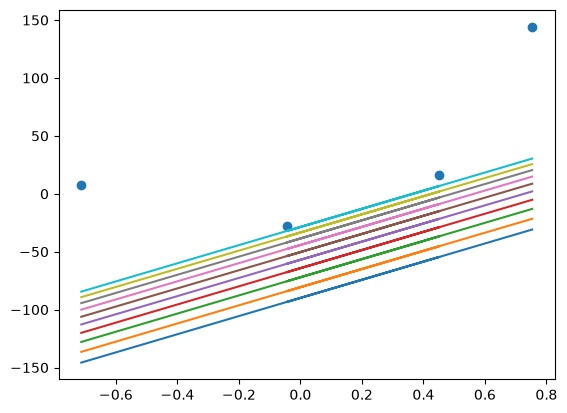

In [37]:
b = -100
m = 78.35
lr = 0.01

epochs = 10

for i in range(epochs):
    loss_slppoe = -2* np.sum(y-m*X.ravel()- b)
    step_size = loss_slppoe*lr
    b = b - step_size
    # print('Epoch: {}, b: {}'.format(i, b))
    y_pred = m * X + b
    plt.plot(X, y_pred)
    
plt.scatter(X, y)
# plt.plot(X, model.predict(X), color='black', label='OLS')
# plt.plot(X, y_pred, color='red', label='b = {}'.format(b))
# plt.legend()
# plt.show()  